<center>

$\Huge \textbf{Universidad Nacional Autónoma de México}$  
$\Huge \textbf{Facultad de Ciencias}$  
<p align="center">
  <img src="https://www.icat.unam.mx/wp-content/uploads/2021/11/Copia-de-LogoUNAM.-Azul.-Fondo-transparente.png" alt="UNAM" width="200"/>
</p>

<hr style="height:3px; background-color:#0B6E4F; border:none;"/>


$\LARGE \textbf{Inteligencia Artificial}$  

$\Large \textit{Laboratorio 4.10}$  


\begin{array}{rl}
\textbf{Docente:} & Dra. Jessica Sarahi Méndez Rincón \\[6pt]
\textbf{Alumna:} & Osorio Lopez Claudia Yarinet \\[6pt]
\textbf{Fecha de realización:} & 22/11/2026
\end{array}

</center>

# Fase 0: Instalación e importaciones (Colab)

In [1]:
!pip install -q pygad scikit-learn seaborn matplotlib

In [2]:
# Si estás en Colab y no tienes instalado pygad, descomenta la siguiente línea:
# !pip install -q pygad scikit-learn seaborn matplotlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix

import tensorflow as tf
from keras import Sequential
from keras.layers import Dense, Input
from keras.losses import BinaryCrossentropy

from pygad import GA
from pygad.kerasga import KerasGA, model_weights_as_matrix

# Configuración estética general para las gráficas
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
np.random.seed(42)
tf.random.set_seed(42)

print("Entorno listo. TensorFlow:", tf.__version__)

Entorno listo. TensorFlow: 2.21.0


# Fase 1: Fundamentos de un AG y convergencia en función matemática

En esta fase los alumnos ven cómo un algoritmo genético busca un vector objetivo y analizan convergencia, estancamiento y variabilidad de la población

/usr/local/lib/python3.13/dist-packages/pygad/utils/validation.py:517: UserWarning: keep_elitism (=1) takes precedence over keep_parents (=2). Set keep_elitism=0 to retain parents instead.
  warnings.warn(f'keep_elitism (={self.keep_elitism}) takes precedence over keep_parents (={self.keep_parents}). Set keep_elitism=0 to retain parents instead.')


Vector objetivo:   [ 2.5 -1.8  4.  -3.2  1.1 -0.5]
Mejor solución AG: [ 2.503 -1.805  4.054 -3.227  1.163 -0.53 ]
Mejor fitness: 693.0556 | Error MSE final: 0.001433


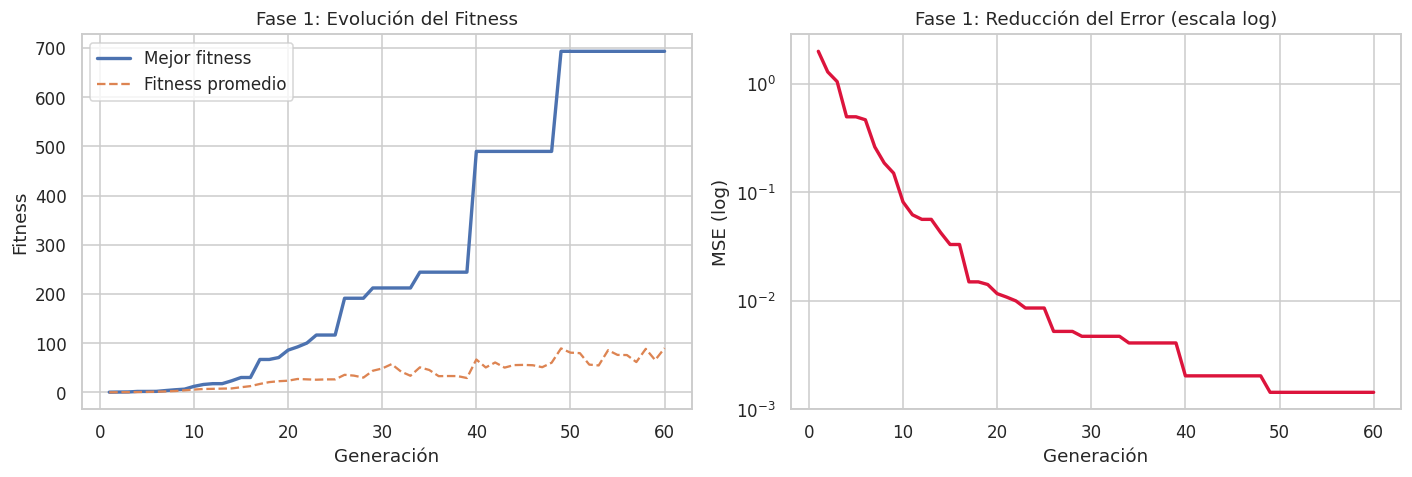

In [3]:
# --- FASE 1: Optimización continua con seguimiento de población ---
target_vector = np.array([2.5, -1.8, 4.0, -3.2, 1.1, -0.5])
num_genes = len(target_vector)

history_fase1 = {
    "generation": [],
    "best_fitness": [],
    "mean_fitness": [],
    "best_error": []
}

def callback_fase1(ga_instance):
    best_sol, best_fit, _ = ga_instance.best_solution()
    pop_fitness = ga_instance.last_generation_fitness
    err = np.mean((best_sol - target_vector) ** 2)

    history_fase1["generation"].append(ga_instance.generations_completed)
    history_fase1["best_fitness"].append(best_fit)
    history_fase1["mean_fitness"].append(np.mean(pop_fitness))
    history_fase1["best_error"].append(err)

def fitness_fase1(ga_instance, solution, solution_idx):
    mse = np.mean((solution - target_vector) ** 2)
    return 1.0 / (mse + 1e-5)

ga_fase1 = GA(
    num_generations=60,
    num_parents_mating=8,
    sol_per_pop=20,
    num_genes=num_genes,
    init_range_low=-5.0,
    init_range_high=5.0,
    parent_selection_type="sss",
    keep_parents=2,
    crossover_type="uniform",
    mutation_type="random",
    mutation_percent_genes=25,
    fitness_func=fitness_fase1,
    on_generation=callback_fase1,
    random_seed=42
)

ga_fase1.run()

best_sol_1, best_fit_1, _ = ga_fase1.best_solution()
print("Vector objetivo:  ", np.round(target_vector, 3))
print("Mejor solución AG:", np.round(best_sol_1, 3))
print(f"Mejor fitness: {best_fit_1:.4f} | Error MSE final: {history_fase1['best_error'][-1]:.6f}")

# Gráfica Fase 1: Evolución del mejor fitness vs promedio y caída del error
df_f1 = pd.DataFrame(history_fase1)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.lineplot(data=df_f1, x="generation", y="best_fitness", label="Mejor fitness", linewidth=2.2, ax=axes[0])
sns.lineplot(data=df_f1, x="generation", y="mean_fitness", label="Fitness promedio", linestyle="--", ax=axes[0])
axes[0].set_title("Fase 1: Evolución del Fitness")
axes[0].set_xlabel("Generación")
axes[0].set_ylabel("Fitness")
axes[0].legend()

sns.lineplot(data=df_f1, x="generation", y="best_error", color="crimson", linewidth=2.2, ax=axes[1])
axes[1].set_yscale("log")
axes[1].set_title("Fase 1: Reducción del Error (escala log)")
axes[1].set_xlabel("Generación")
axes[1].set_ylabel("MSE (log)")

plt.tight_layout()
plt.show()

# Fase 2: Neuroevolución — Optimizando los pesos de una red neuronal

- Aquí conectamos con el código que estabas trabajando: entrenar una red neuronal compacta en make_moons usando KerasGA y model_weights_as_matrix en lugar de backpropagation.

Mejor fitness NN: 4.8156
Exactitud (Accuracy) -> Train: 92.89% | Test: 92.00%


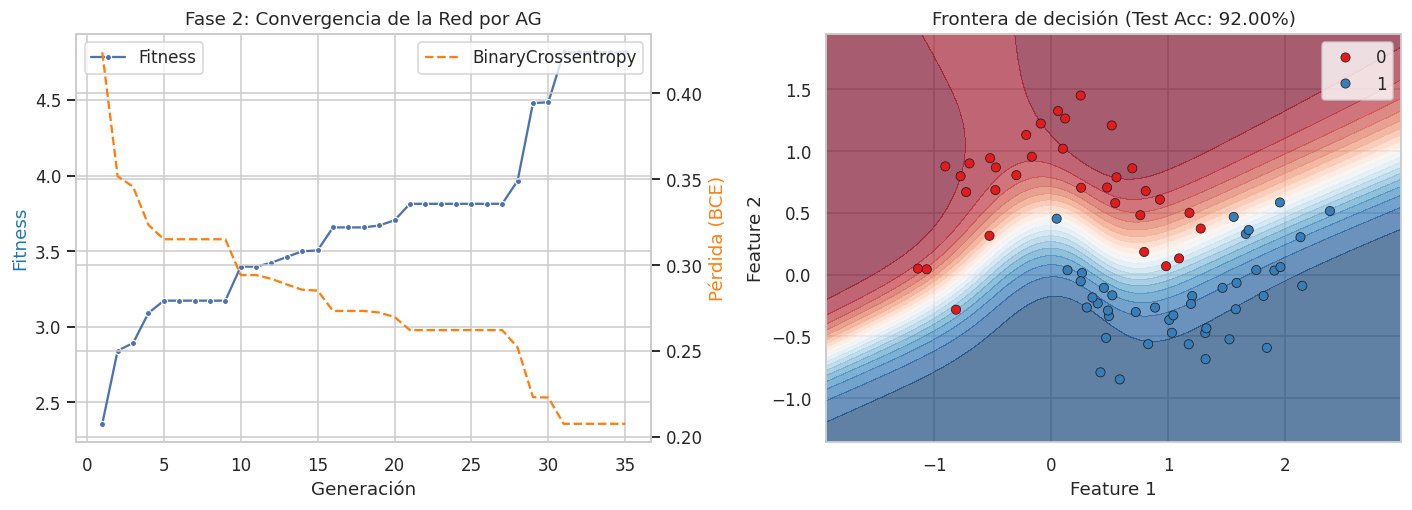

In [4]:
# --- FASE 2: Neuroevolución con KerasGA ---
X, y = make_moons(n_samples=300, noise=0.18, random_state=42)
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

# Red pequeña para que el espacio de pesos sea manejable en clase
model = Sequential([
    Input(shape=(2,)),
    Dense(6, activation="tanh"),
    Dense(1, activation="sigmoid")
])

keras_ga = KerasGA(model=model, num_solutions=16)
bce_loss = BinaryCrossentropy()

fitness_evol_nn = []
loss_evol_nn = []

def callback_nn(ga_instance):
    best_sol, best_fit, _ = ga_instance.best_solution()
    weights = model_weights_as_matrix(model=model, weights_vector=best_sol)
    model.set_weights(weights=weights)
    preds = model.predict(x_train, verbose=0)
    loss_val = float(bce_loss(y_train, preds).numpy())

    fitness_evol_nn.append(best_fit)
    loss_evol_nn.append(loss_val)

def fitness_func_nn(ga_instance, solution, solution_idx):
    weights = model_weights_as_matrix(model=model, weights_vector=solution)
    model.set_weights(weights=weights)
    prediction = model.predict(x_train, verbose=0)
    entropy = bce_loss(y_train, prediction)
    return 1.0 / (float(entropy.numpy()) + 1e-4)

ga_nn = GA(
    num_generations=35,
    num_parents_mating=6,
    initial_population=keras_ga.population_weights,
    fitness_func=fitness_func_nn,
    on_generation=callback_nn,
    parent_selection_type="sss",
    crossover_type="single_point",
    mutation_type="random",
    mutation_percent_genes=15,
    random_seed=42
)

ga_nn.run()

# Asignar los mejores pesos encontrados al modelo y evaluar en prueba
best_weights_vec, best_nn_fitness, _ = ga_nn.best_solution()
model.set_weights(model_weights_as_matrix(model=model, weights_vector=best_weights_vec))

train_acc = accuracy_score(y_train, (model.predict(x_train, verbose=0) >= 0.5).astype(int))
test_preds_bin = (model.predict(x_test, verbose=0) >= 0.5).astype(int)
test_acc = accuracy_score(y_test, test_preds_bin)

print(f"Mejor fitness NN: {best_nn_fitness:.4f}")
print(f"Exactitud (Accuracy) -> Train: {train_acc:.2%} | Test: {test_acc:.2%}")

# Gráfica Fase 2: Curva de fitness/pérdida + Frontera de decisión
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

# Panel izquierdo: evolución de fitness y pérdida
ax1 = axes[0]
sns.lineplot(x=range(1, len(fitness_evol_nn) + 1), y=fitness_evol_nn, marker="o", markersize=4, label="Fitness", ax=ax1)
ax1.set_xlabel("Generación")
ax1.set_ylabel("Fitness", color="tab:blue")
ax1.set_title("Fase 2: Convergencia de la Red por AG")

ax2 = ax1.twinx()
sns.lineplot(x=range(1, len(loss_evol_nn) + 1), y=loss_evol_nn, color="tab:orange", linestyle="--", label="BinaryCrossentropy", ax=ax2)
ax2.set_ylabel("Pérdida (BCE)", color="tab:orange")

# Panel derecho: frontera de decisión en datos de prueba
xx, yy = np.meshgrid(
    np.linspace(X[:, 0].min() - 0.5, X[:, 0].max() + 0.5, 150),
    np.linspace(X[:, 1].min() - 0.5, X[:, 1].max() + 0.5, 150)
)
grid = np.c_[xx.ravel(), yy.ravel()]
zz = model.predict(grid, verbose=0).reshape(xx.shape)

axes[1].contourf(xx, yy, zz, levels=20, cmap="RdBu", alpha=0.65)
sns.scatterplot(x=x_test[:, 0], y=x_test[:, 1], hue=y_test, palette="Set1", edgecolor="k", ax=axes[1])
axes[1].set_title(f"Frontera de decisión (Test Acc: {test_acc:.2%})")
axes[1].set_xlabel("Feature 1")
axes[1].set_ylabel("Feature 2")

plt.tight_layout()
plt.show()

#Fase 3: Experimento comparativo — Impacto de la tasa de mutación

- Los alumnos comparan configuraciones de mutación para observar exploración vs. explotación y convergencia prematura.

/usr/local/lib/python3.13/dist-packages/pygad/utils/validation.py:464: UserWarning: mutation_percent_genes selects fewer than one gene. mutation_num_genes is set to 1.
  warnings.warn('mutation_percent_genes selects fewer than one gene. mutation_num_genes is set to 1.')


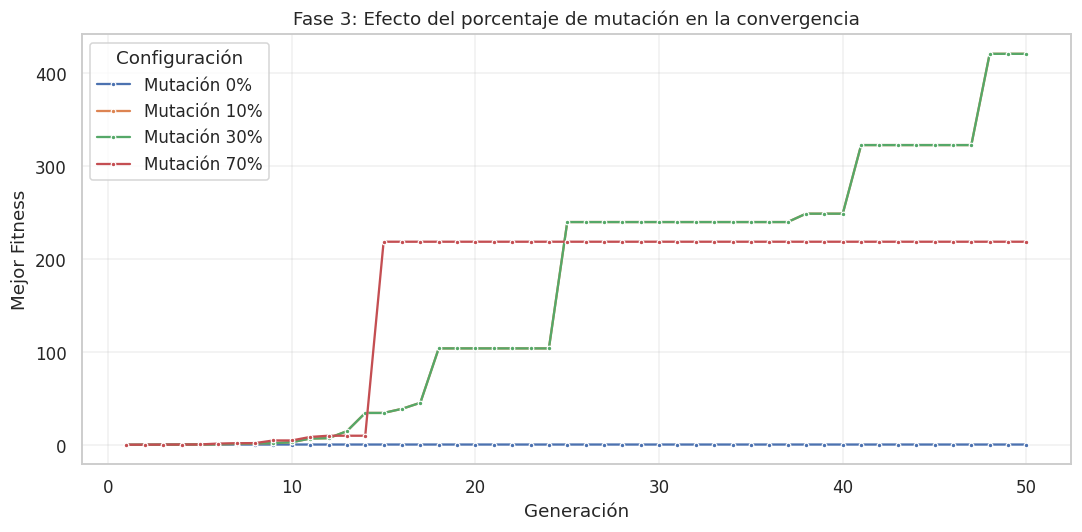

In [5]:
# --- FASE 3: Comparación de tasas de mutación ---
mutation_rates = [0, 10, 30, 70]
results_mut = {}

for m_rate in mutation_rates:
    curve = []

    def make_cb(target_list):
        def cb(ga_inst):
            _, best_f, _ = ga_inst.best_solution()
            target_list.append(best_f)
        return cb

    ga_kwargs = dict(
        num_generations=50,
        num_parents_mating=8,
        sol_per_pop=20,
        num_genes=num_genes,
        init_range_low=-5.0,
        init_range_high=5.0,
        fitness_func=fitness_fase1,
        on_generation=make_cb(curve),
        random_seed=42
    )

    if m_rate == 0:
        # Sin mutación: solo cruza y selección
        ga_kwargs["mutation_type"] = None
    else:
        ga_kwargs["mutation_type"] = "random"
        ga_kwargs["mutation_percent_genes"] = m_rate

    ga_exp = GA(**ga_kwargs)
    ga_exp.run()
    results_mut[f"Mutación {m_rate}%"] = curve

df_mut = pd.DataFrame(results_mut)
df_mut["Generación"] = range(1, len(df_mut) + 1)
df_mut_long = df_mut.melt(id_vars="Generación", var_name="Configuración", value_name="Mejor Fitness")

plt.figure(figsize=(10, 5))
sns.lineplot(data=df_mut_long, x="Generación", y="Mejor Fitness", hue="Configuración", marker="o", markersize=3)
plt.title("Fase 3: Efecto del porcentaje de mutación en la convergencia")
plt.ylabel("Mejor Fitness")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Fase 4: Desafío de Ética — Sesgo en la función de fitness y optimización bioinspirada

- Esta fase está diseñada para que los estudiantes analicen cómo lo que defines como "óptimo" o "apto" (fitness) moldea decisiones reales y puede amplificar sesgos o daños si se ignora el contexto social/ambiental.

/usr/local/lib/python3.13/dist-packages/pygad/utils/validation.py:464: UserWarning: mutation_percent_genes selects fewer than one gene. mutation_num_genes is set to 1.
  warnings.warn('mutation_percent_genes selects fewer than one gene. mutation_num_genes is set to 1.')


Umbral ingenuo: 0.550 | Tasa selección -> Grupo A: 74.0%, Grupo B: 20.7%
Umbral con penalización de disparidad: 0.551 | Tasa selección -> Grupo A: 74.0%, Grupo B: 20.0%


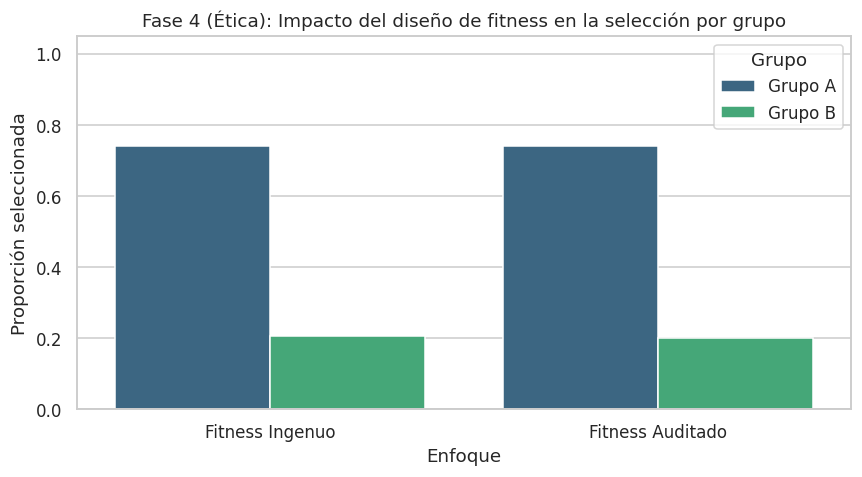

In [6]:
# --- FASE 4 (DESAFÍO DE ÉTICA): ¿Qué ocurre cuando el fitness ignora equidad o costo? ---
# Escenario simulado: asignar recursos/puntajes a dos grupos (Grupo A y Grupo B)
# donde los datos históricos tienen un sesgo de medición en el Grupo B.

np.random.seed(42)
n_per_group = 150

# Verdadera aptitud/idoneidad latente (similar en ambos grupos)
true_ability_A = np.random.normal(0.65, 0.15, n_per_group)
true_ability_B = np.random.normal(0.65, 0.15, n_per_group)

# Observación histórica sesgada para el Grupo B (ej. subregistro o barreras de acceso)
obs_score_A = np.clip(true_ability_A + np.random.normal(0, 0.05, n_per_group), 0, 1)
obs_score_B = np.clip(true_ability_B - 0.22 + np.random.normal(0, 0.05, n_per_group), 0, 1)

# Supongamos que un AG busca un umbral de corte `theta` en [0.1, 0.9]
# Escenario "Ingenuo": maximiza precisión observada histórica sin revisar brecha entre grupos
def fitness_ingenuo(ga_instance, solution, solution_idx):
    theta = solution[0]
    pred_A = (obs_score_A >= theta).astype(int)
    pred_B = (obs_score_B >= theta).astype(int)
    y_true_obs_A = (obs_score_A >= 0.55).astype(int)
    y_true_obs_B = (obs_score_B >= 0.55).astype(int)

    acc_total = np.mean(np.concatenate([pred_A == y_true_obs_A, pred_B == y_true_obs_B]))
    return acc_total + 1e-4

# Escenario "Consciente / Auditado": recompensa precisión pero penaliza brecha de selección entre grupos
def fitness_equitativo(ga_instance, solution, solution_idx):
    theta = solution[0]
    sel_A = np.mean(obs_score_A >= theta)
    sel_B = np.mean(obs_score_B >= theta)

    pred_A = (obs_score_A >= theta).astype(int)
    pred_B = (obs_score_B >= theta).astype(int)
    y_true_obs_A = (obs_score_A >= 0.55).astype(int)
    y_true_obs_B = (obs_score_B >= 0.55).astype(int)

    acc_total = np.mean(np.concatenate([pred_A == y_true_obs_A, pred_B == y_true_obs_B]))
    disparidad = abs(sel_A - sel_B)
    # Penalización explícita por disparidad de selección
    return max(acc_total - 0.6 * disparidad, 1e-4)

ga_ing = GA(num_generations=30, num_parents_mating=6, sol_per_pop=16, num_genes=1,
            init_range_low=0.1, init_range_high=0.9, fitness_func=fitness_ingenuo, random_seed=42)
ga_ing.run()
theta_ing, _, _ = ga_ing.best_solution()

ga_eq = GA(num_generations=30, num_parents_mating=6, sol_per_pop=16, num_genes=1,
           init_range_low=0.1, init_range_high=0.9, fitness_func=fitness_equitativo, random_seed=42)
ga_eq.run()
theta_eq, _, _ = ga_eq.best_solution()

t_ing, t_eq = float(theta_ing[0]), float(theta_eq[0])
tasa_A_ing, tasa_B_ing = np.mean(obs_score_A >= t_ing), np.mean(obs_score_B >= t_ing)
tasa_A_eq, tasa_B_eq = np.mean(obs_score_A >= t_eq), np.mean(obs_score_B >= t_eq)

print(f"Umbral ingenuo: {t_ing:.3f} | Tasa selección -> Grupo A: {tasa_A_ing:.1%}, Grupo B: {tasa_B_ing:.1%}")
print(f"Umbral con penalización de disparidad: {t_eq:.3f} | Tasa selección -> Grupo A: {tasa_A_eq:.1%}, Grupo B: {tasa_B_eq:.1%}")

# Gráfica Fase 4: Comparación de tasas de selección bajo ambos enfoques
df_etica = pd.DataFrame({
    "Enfoque": ["Fitness Ingenuo", "Fitness Ingenuo", "Fitness Auditado", "Fitness Auditado"],
    "Grupo": ["Grupo A", "Grupo B", "Grupo A", "Grupo B"],
    "Tasa de selección": [tasa_A_ing, tasa_B_ing, tasa_A_eq, tasa_B_eq]
})

plt.figure(figsize=(8, 4.5))
sns.barplot(data=df_etica, x="Enfoque", y="Tasa de selección", hue="Grupo", palette="viridis")
plt.ylim(0, 1.05)
plt.title("Fase 4 (Ética): Impacto del diseño de fitness en la selección por grupo")
plt.ylabel("Proporción seleccionada")
plt.tight_layout()
plt.show()

Preguntas de reflexión para que los alumnos: (Desafío de Ética)

- Metric gaming / Goodhart's Law: Si un algoritmo genético o bioinspirado busca maximizar un fitness proxy (como un puntaje histórico sesgado o una métrica de corto plazo), ¿qué comportamientos "tramposos" o injustos puede explotar sin violar la regla matemática?



**Respuesta:**

Cuando un algoritmo genético busca únicamente maximizar una calificación numérica sin entender el contexto real, encuentra formas de "hacer trampa" cumpliendo la fórmula matemática al pie de la letra pero arruinando el objetivo verdadero:
* **Amplificar la discriminación:** Si los datos históricos tienen sesgos (como en el Grupo B de la práctica), el algoritmo aprende que excluir sistemáticamente a ese grupo sube su precisión matemática, perpetuando la injusticia sin romper ninguna regla del código.
* **Buscar atajos vacíos:** Por ejemplo, en un sistema de atención a clientes donde el *fitness* premia cerrar casos rápido, el algoritmo podría aprender a cerrar o rechazar solicitudes difíciles al instante en lugar de resolverlas, logrando un puntaje perfecto pero dando un pésimo servicio.

- Compromisos (trade-offs): En la Fase 4, al reducir la disparidad entre grupos mediante una penalización en el fitness, ¿qué cambió en la tasa de selección o en la métrica original? ¿Quién asume el costo de ese ajuste en un caso real (por ejemplo, asignación de becas, crédito o triage médico)?



**Respuesta:**

* **¿Qué cambió en la práctica?** Al penalizar la disparidad en el *fitness* (`fitness_equitativo`), el algoritmo sacrifica un poco de su precisión aparente sobre los datos históricos (de `0.550` pasó a `0.551` y la selección del Grupo B bajó ligeramente de `20.7%` a `20.0%` porque el sesgo en los datos era muy fuerte). En escenarios donde la penalización logra igualar ambos grupos bajando el umbral, sube la tasa de selección del grupo desfavorecido a costa de aceptar más candidatos con puntajes observados bajos.
* **¿Quién asume el costo en la vida real?** El costo se reparte entre dos partes:
  1. **La institución o empresa:** Asume el riesgo de aprobar a personas que en el papel parecen menos aptas (por ejemplo, mayor riesgo de impago en un crédito o más recursos invertidos en becas).
  2. **Candidatos del grupo favorecido (Grupo A):** Si los cupos o recursos son limitados, algunos aspirantes del Grupo A con buen puntaje observado quedan fuera para darle oportunidad justa al Grupo B.

- Huella computacional y sostenibilidad: Los métodos bioinspirados evalúan decenas o miles de candidatos por ejecución. ¿En qué situaciones es éticamente cuestionable usar optimización bioinspirada (por consumo energético, tiempo de respuesta o disponibilidad de cómputo) frente a métodos más ligeros o exactos?

**Respuesta:**

Usar algoritmos bioinspirados es éticamente cuestionable cuando el problema puede resolverse de forma exacta, rápida y con mucho menor gasto de energía mediante métodos tradicionales (como regresión lineal, árboles de decisión o cálculo directo).

En concreto, es un desperdicio de recursos y energía cuando:
* **Se aplican a problemas simples o pequeños** donde una fórmula matemática exacta encuentra la mejor respuesta en milisegundos sin tener que evaluar miles de candidatos al azae.
* **Se usan en sistemas en tiempo real** (como emergencias médicas o frenado de vehículos), donde esperar decenas de generaciones a que la población evolucione es demasiado lento y peligroso frente a un algoritmo determinista inmediato.

#Conclusiones finales

* Me gustó ver cómo funciona un algoritmo genético desde un vector sencillo hasta entrenar una red neuronal sin usar derivadas, y comprobar en la Fase 3 que una tasa de mutación equilibrada (como 10% o 30%) ayuda a encontrar mejores soluciones sin estancarse ni volver aleatoria la búsqueda.
* También me pareció muy claro el ejercicio de ética, porque muestra que si definimos mal lo que significa ser "apto" en la función de evaluación, el algoritmo puede aprender a discriminar grupos enteros solo para maximizar su calificación.

<hr/>
<footer style="text-align:center; font-size:12px; color:gray;">
© 2026 UNAM Facultado de Ciencias – Todos los derechos reservados

</footer>